In [7]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
DATA_DIR = Path(r"C:\Users\Jordi\Desktop\Trading\quant_lab\data\raw_reverse_adjusted")
COLUMNS = ["date", "open", "high", "low", "close", "volume", "interest"]


resultats = []
for x in sorted(DATA_DIR.glob("*.CSV")):
    code = x.stem.removesuffix("_REV")
    actif = pd.read_csv(x, names=COLUMNS)
    actif["date"] = pd.to_datetime(actif["date"], format="%m/%d/%Y")

    first_date = actif["date"].min()
    last_date = actif["date"].max()
    jours_ouvres = len(pd.bdate_range(first_date, last_date))

    resultats.append({
        "code": code,
        "first_date": first_date,
        "last_date": last_date,
        "n_rows": len(actif),
        "max_gap_days": actif["date"].diff().max().days,
        "pct_missing": round(100 * (1 - len(actif) / jours_ouvres), 1),
        "min_close": actif["close"].min(),
    })

inventaire = pd.DataFrame(resultats).set_index("code")
inventaire

ValueError: Neither `start` nor `end` can be NaT

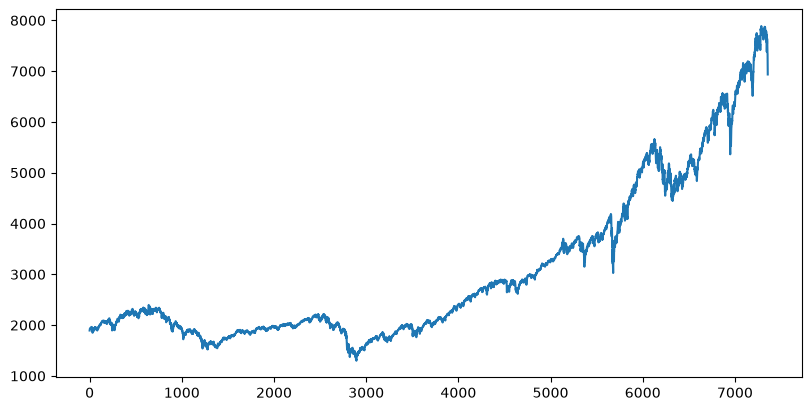

In [12]:
# Print du contrat futur mini du SP 

fg, ax = plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(ES["close"])